In [98]:
%pip install --quiet beautifulsoup4 requests pandas selenium webdriver-manager

Note: you may need to restart the kernel to use updated packages.


In [99]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
import time
import json


Status code: 200 OK
Content type: text/html; charset=utf-8
Text: <!DOCTYPE html>
<html lang="en-gb"  style="min-height: 100%;">
    <head>
        <meta charset="utf-8">
        <meta http-equiv="X-UA-Compatible" content="IE=edge">
        <meta name="viewport" content="width=device-width, initial-scale=1">
        <!-- Pocket-152 | DIY Fix -->
<style>
.headerBoxLayout .pageHeadingBox{
display:none!important;
}

</style><!-- Pocket-10 | Function Fixes -->
<style>
/* 
 * Function Fixes 
 */
[class$="ContributionItem-classes-listItem"] a[title="Spam"],  /* Foundation only [comment/79400481] */
.IgnoreHide, /* [comment/79400486] */
.ReactButton-Flag .Count, /*  [comment/79400448] */
.editor-dd-fileupload /*  [comment/79400483] */
{display: none !important}

/* Activity Section [comment/79400446] */
form.Activity,
.DataList.Activities,
.DataListWrap .FormWrapper {
    display: none !important;
}
.DataList.Activities.Notifications {
    display: block !important;
}

/* Reaction Swapper [com
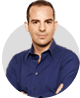
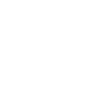
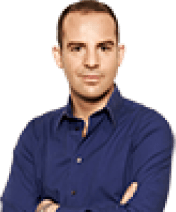
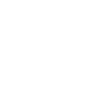
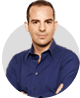
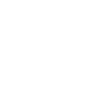
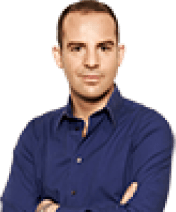
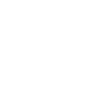

In [100]:
# Check the response from the website and print the status code, content type, and the text that was returned

url = "https://forums.moneysavingexpert.com/categories/benefits-tax-credits"

response = requests.get(url)

print(f"Status code: {response.status_code} {response.reason}")
print(f"Content type: {response.headers.get('Content-Type', 'unknown')}")
print(f"Text: {response.text}")

In [101]:
# Get links from the linkList class and print them out
soup = BeautifulSoup(requests.get("https://forums.moneysavingexpert.com/categories/benefits-tax-credits/p2").text, "html.parser")
thread_links = soup.find_all("ul", class_="linkList")
print(thread_links)


[<ul class="linkList"><li>
<a href="https://forums.moneysavingexpert.com/discussion/6685333/tribunal-awarded-pip-when-to-expect-first-payment">Tribunal awarded PIP - when to expect first payment?</a>
<p>So after a long and stressful process, my wife was finally awarded PIP at the tribunal hearing. The hearing took place on 7th September. In the same week we received a letter from HMCTS confirming the decision. But it's now almost four weeks and we've yet to hear from DWP about the payments. My wife will be due at least a…</p>
</li>
<li>
<a href="https://forums.moneysavingexpert.com/discussion/6685173/uc-treatment-of-income-when-assessing-capital-in-an-ap">UC: Treatment of income when assessing capital in an AP</a>
<p>This is a topic that has been discussed a few times on this forum, and there is currently a thread on rightsnet that some may be interested in following: https://www.rightsnet.org.uk/forums/viewthread/22070/ The relevant guidance is in ADM H1050 which states income becomes

In [102]:
# As there is 2 linkLists on each page, we will just get the first one using find() and then get the links from that list using find_all("li"). 

soup = BeautifulSoup(requests.get("https://forums.moneysavingexpert.com/categories/benefits-tax-credits/").text, "html.parser")
thread_links = soup.find("ul", class_="linkList").find_all("li")
print(thread_links)

[<li>
<a href="https://forums.moneysavingexpert.com/discussion/365935/its-about-helping-people-get-their-entitlement-not-about-benefits-policy">Its about helping people get their entitlement! Not about benefits policy!</a>
<p>Its about helping people get their entitlement! Not about benefits policy! This board is here for help and support for those on or looking to claim benefits, not for judgement. Its ONLY focus is helping people with their money. It's here to help people find out what they are entitled to under the current system, and to…</p>
</li>, <li>
<a href="https://forums.moneysavingexpert.com/discussion/1215/useful-links">*USEFUL LINKS*</a>
<p>MoneySavingExpert insert: Huge thanks to Fran for compiling this list some time ago. The MSE article and forum links are up to date but links to other sites may be broken. Back to Fran's original post: ---- The following links may prove useful in looking for information about Benefits and Jobseeking. MSE Attendance…</p>
</li>, <li>
<a h

In [103]:
links = []

for thread in thread_links[:5]:  # Limit to 5 for demonstration
    link = thread.find("a")["href"]
    links.append(link)
    print(f"Found thread link: {link}")

    time.sleep(1)  # Respectful delay

links


Found thread link: https://forums.moneysavingexpert.com/discussion/365935/its-about-helping-people-get-their-entitlement-not-about-benefits-policy
Found thread link: https://forums.moneysavingexpert.com/discussion/1215/useful-links
Found thread link: https://forums.moneysavingexpert.com/discussion/6685452/capital-was-in-my-to-do-list-but-it-doesnt-show-in-my-journal
Found thread link: https://forums.moneysavingexpert.com/discussion/6687069/esa-contribution-based-help-with-rent-uc-housing-element
Found thread link: https://forums.moneysavingexpert.com/discussion/6684323/uc-review-again


['https://forums.moneysavingexpert.com/discussion/365935/its-about-helping-people-get-their-entitlement-not-about-benefits-policy',
 'https://forums.moneysavingexpert.com/discussion/1215/useful-links',
 'https://forums.moneysavingexpert.com/discussion/6685452/capital-was-in-my-to-do-list-but-it-doesnt-show-in-my-journal',
 'https://forums.moneysavingexpert.com/discussion/6687069/esa-contribution-based-help-with-rent-uc-housing-element',
 'https://forums.moneysavingexpert.com/discussion/6684323/uc-review-again']

In [104]:
# There are 2 links at the top of teh first page which are pinned. They are Closed and Annoucements.
# There doesn't seem to be any way to identify the pinned threads from the html
# Searching teh page source for "pinned" and "aanouncement" shows it is present in <div class="" data-react="DiscussionListModule" data-props="PRESENT HERE"
# So I will extract that and see what it contains.

soup = BeautifulSoup(requests.get("https://forums.moneysavingexpert.com/categories/benefits-tax-credits/").text, "html.parser")


# Beutiful Soup Documentation:
# data_soup.find_all(attrs={"data-foo": "value"})
# [<div data-foo="value">foo!</div>]

data_props = soup.find_all("div", attrs={"data-props": True})






In [105]:
data_props

[<div class="" data-props='{"description":"Get help discovering which benefits you are entitled to - and how to claim them.","backgroundImage":"https:\/\/us-noi.v-cdn.net\/6031891\/uploads\/MHWWETUWXZYC\/work-business-benefits.jpg","iconImage":"https:\/\/us-noi.v-cdn.net\/6031891\/uploads\/9ZWSVNP2QEAH\/icon-benefits-taxcredits.svg","iconUrlSrcSet":{"300":"https:\/\/us-noi.v-cdn.net\/cdn-cgi\/image\/quality=80,format=auto,fit=scale-down,height=300,width=300\/6031891\/uploads\/9ZWSVNP2QEAH\/icon-benefits-taxcredits.svg","600":"https:\/\/us-noi.v-cdn.net\/cdn-cgi\/image\/quality=80,format=auto,fit=scale-down,height=600,width=600\/6031891\/uploads\/9ZWSVNP2QEAH\/icon-benefits-taxcredits.svg","800":"https:\/\/us-noi.v-cdn.net\/cdn-cgi\/image\/quality=80,format=auto,fit=scale-down,height=800,width=800\/6031891\/uploads\/9ZWSVNP2QEAH\/icon-benefits-taxcredits.svg","1200":"https:\/\/us-noi.v-cdn.net\/cdn-cgi\/image\/quality=80,format=auto,fit=scale-down,height=1200,width=1200\/6031891\/upload

In [106]:
# I copied this into Claude to see how to extract the data-props and it said to use the following code:

props = json.loads(div["data-props"])  


In [107]:
props

{'apiParams': {'rand': '06SYCTQEH8'},
 'discussions': [{'discussionID': 365935,
   'type': 'discussion',
   'name': 'Its about helping people get their entitlement! Not about benefits policy!',
   'excerpt': "Its about helping people get their entitlement! Not about benefits policy! This board is here for help and support for those on or looking to claim benefits, not for judgement. Its ONLY focus is helping people with their money. It's here to help people find out what they are entitled to under the current system, and to…",
   'categoryID': 139,
   'dateInserted': '2007-02-01T23:24:06+00:00',
   'dateUpdated': '2023-02-14T11:11:38+00:00',
   'dateLastComment': '2010-12-15T08:59:47+00:00',
   'insertUserID': 13175,
   'insertUser': {'userID': 13175,
    'name': 'MSE_Martin',
    'url': 'https://forums.moneysavingexpert.com/profile/MSE_Martin',
    'photoUrl': 'https://us-noi.v-cdn.net/6031891/uploads/defaultavatar/nFA7H6UNOO0N5.jpg',
    'dateLastActive': '2024-05-03T17:07:19+00:00',

In [112]:
# This gives a list of dictionaries. Extract first to inspect

first_thread = props["discussions"][0]

In [117]:
# The above disctionnary is for each thread on the page. 
# We can extract the url, pinned, and annoucement from the dictionary.
# countViews may be useful to identify the most popular threads assuming it is a count of the number of views for the thread.
# countComments may be useful to identify the most popular threads assuming it is a count of the number of comments for the thread.
url = first_thread["url"]
pinned = first_thread["pinned"]
announcement = first_thread["announce"]
count_views = first_thread["countViews"]
count_comments = first_thread["countComments"]

print(f"URL: {url}")
print(f"Count Views: {count_views}, Count Comments: {count_comments}")
print(f"Pinned: {pinned}, Announcement: {announcement}")

URL: https://forums.moneysavingexpert.com/discussion/365935/its-about-helping-people-get-their-entitlement-not-about-benefits-policy
Count Views: 122327, Count Comments: 1
Pinned: True, Announcement: True


In [ ]:
# Initially we could scarape the pages of the forum 
# Get the url for those which are not pinned and annoucements 
# Create a dataframe with the url, countViews, countComments, pinned, and annoucement

# Then we create another scraper to scrape those urls and get the text of the posts 
# (not sure if we should get comments by other users as well or just the original post).. need to do some research



In [ ]:
# How do the urls look for the pages of the forum:
# First page: https://forums.moneysavingexpert.com/categories/benefits-tax-credits/
# Second page: https://forums.moneysavingexpert.com/categories/benefits-tax-credits/p2
# n pages: https://forums.moneysavingexpert.com/categories/benefits-tax-credits/pn

# There is also a "Next" button at the bottom of the page which links to the next page. 
# It shows the maxium number of pages available. We can use this to get the top end limit - curent this forum has 3807 pages, so we wouldn't want to scrape all of them. 
# We can limit it to the first X pages in teh code 


soup = BeautifulSoup(requests.get("https://forums.moneysavingexpert.com/categories/benefits-tax-credits/").text, "html.parser")


In [138]:
# First we should create a ethical scraper which respects the robots.txt file and the terms of service of the website.

class RespectfulScraper:
    """
    A web scraper that respects robots.txt rules and rate limits.

    This class automatically:
    - Parses robots.txt for the target domain
    - Enforces crawl delays between requests
    - Identifies itself with a descriptive User-Agent string
    - Logs all activity for transparency and debugging
    """

    def __init__(self, base_url: str, default_delay: int = 3):
        self.base_url = base_url.rstrip("/")

        # Create a session for connection reuse and consistent headers
        self.session = requests.Session()
        self.session.headers.update({
            "User-Agent": "BPP-DataScience-Bot/1.0 (educational project)"
        })

        # Set up logging
        self.logger = logging.getLogger(f"scraper.{urlparse(base_url).hostname}")
        self.logger.setLevel(logging.INFO)

        # Parse robots.txt
        self.rp = RobotFileParser()
        self.rp.set_url(f"{self.base_url}/robots.txt")

        try:
            self.rp.read()
            self.logger.info("Successfully parsed robots.txt")
        except Exception as e:
            self.logger.warning(f"Could not read robots.txt: {e}")

        # Get crawl delay: use robots.txt value, or fall back to default
        delay = self.rp.crawl_delay(self.session.headers["User-Agent"])
        self.crawl_delay = int(delay) if delay else default_delay
        self.logger.info(f"Using crawl delay of {self.crawl_delay}s")

    def can_fetch(self, url: str) -> bool:
        """Check if a URL is allowed by robots.txt."""
        return self.rp.can_fetch(self.session.headers["User-Agent"], url)

    def get(self, url: str) -> Optional[BeautifulSoup]:
        """
        Fetch and parse a page, respecting robots.txt and crawl delays.

        Returns a BeautifulSoup object if successful, None otherwise.
        """
        if not self.can_fetch(url):
            self.logger.warning(f"Blocked by robots.txt: {url}")
            return None

        try:
            self.logger.info(f"Fetching {url}")
            response = self.session.get(url, timeout=10)
            response.raise_for_status()

            # Respect crawl delay
            time.sleep(self.crawl_delay)

            return BeautifulSoup(response.text, "html.parser")

        except requests.exceptions.RequestException as e:
            self.logger.error(f"Error fetching {url}: {e}")
            return None

In [ ]:
# I search the source for next page and it lives in here:
# <a href="https://forums.moneysavingexpert.com/categories/benefits-tax-credits/p2" class="Next" tabindex="0" rel="nofollow next" title="Next Page" aria-label="Next Page">»</a></div><div class="ButtonGroup discussion-sort-filter-module pull-left">

In [132]:
# Could get the next page link from the soup using the following code:
next_page_link = soup.find("a", class_="Next")
print(f"Next page URL: {next_page_url}")

Next page URL: https://forums.moneysavingexpert.com/categories/benefits-tax-credits/p2


In [180]:

FORUM_URL = "https://forums.moneysavingexpert.com/categories/benefits-tax-credits"
NUMBER_OF_PAGES_TO_SCRAPE = 4

scraper = RespectfulScraper("https://www.moneysavingexpert.com/", default_delay=1)

# I could set the starter page, and create a loop where it goes trhough that range of pages uisng the next button

url_list = []

# Add the starter page to the list of URLs to scrape
url_list.append(FORUM_URL)

for page in range(1, NUMBER_OF_PAGES_TO_SCRAPE):  # Example: scrape first 5 pages
    url = url_list[-1]  # Get the last URL in the list
    soup = scraper.get(url)
    
    next_page_link = soup.find("a", class_="Next")
    
    # If there is no next page link, break the loop
    if not next_page_link:
        break
    
    next_page_url = next_page_link["href"]
    url_list.append(next_page_url)

In [181]:
url_list

['https://forums.moneysavingexpert.com/categories/benefits-tax-credits',
 'https://forums.moneysavingexpert.com/categories/benefits-tax-credits/p2',
 'https://forums.moneysavingexpert.com/categories/benefits-tax-credits/p3',
 'https://forums.moneysavingexpert.com/categories/benefits-tax-credits/p4']

In [ ]:
# Scraper for each page of the forum to extract the thread data (url, pinned, announcement, countViews, countComments)

thread_data = []

for page_url in url_list:
    page_soup = scraper.get(page_url)

    for dataprops in page_soup.find_all("div", attrs={"data-props": True}):
        props = json.loads(dataprops["data-props"])

        for thread in props.get("discussions", []):
            thread_data.append({
                "url": thread.get("url"),
                "pinned": thread.get("pinned"),
                "announcement": thread.get("announce"),
                "count_views": thread.get("countViews"),
                "count_comments": thread.get("countComments"),
            })


In [173]:
thread_data

[{'url': 'https://forums.moneysavingexpert.com/discussion/365935/its-about-helping-people-get-their-entitlement-not-about-benefits-policy',
  'pinned': True,
  'announcement': True,
  'count_views': 122327,
  'count_comments': 1},
 {'url': 'https://forums.moneysavingexpert.com/discussion/1215/useful-links',
  'pinned': True,
  'announcement': True,
  'count_views': 157378,
  'count_comments': 0},
 {'url': 'https://forums.moneysavingexpert.com/discussion/6687159/child-benefit-charge',
  'pinned': False,
  'announcement': False,
  'count_views': 1,
  'count_comments': 0},
 {'url': 'https://forums.moneysavingexpert.com/discussion/6685452/capital-was-in-my-to-do-list-but-it-doesnt-show-in-my-journal',
  'pinned': False,
  'announcement': False,
  'count_views': 1890,
  'count_comments': 48},
 {'url': 'https://forums.moneysavingexpert.com/discussion/6687069/esa-contribution-based-help-with-rent-uc-housing-element',
  'pinned': False,
  'announcement': False,
  'count_views': 155,
  'count_c

In [183]:
# Next I will need to create a scraper for each of the thread urls to get the text of the posts and add it to the thread_data list.

soup = scraper.get("https://forums.moneysavingexpert.com/discussion/6684777/benefits-following-death-savings")

if soup:
    products = soup.find_all("div", class_="Message userContent")
    print(products)

[<div class="Message userContent">
<p>Morning all, sorry if this is the wrong place for this but my 86 year old relative is very upset and kind of desperate for help.</p><p>Her husband (my uncle) died a month or so ago and she is now left trying to sort out her life and finances without his help. Before his death they managed fairly well from a financial standpoint but since his death everything has seemed to fall apart.</p><p>I will be very clear with what she has and doesn't have etc. and if anyone can give me some advice I would be incredibly grateful.</p><p>She has the following assets:</p><ol><li>Her house worth around £200-£250k (this is a guess by me but probably fairly accurate)</li><li>£25k in savings and insurance payouts from my uncles death.</li></ol><p>She had an accident in her 20s and has multiple constructive surgeries in her life reconstructing her legs, as such she is very disabled. She also has very bad breathing issues were she is out of breath within 5 yards, this 

In [ ]:


# I could then merge all the fucntions together to reduce the amount of scraping and make it more efficient.
# ONCE I'VE DONE THIS I CAN THEN COMMIT AND MERGE IT IN!